<a href="https://colab.research.google.com/github/Janith303/Sinhala-and-Maths-Model-training-/blob/opencv-%2BGradient-Boosting/Sinhala_Baseline_OpenCV_GradientBoosting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sinhala Handwriting — Baseline Deviation Detection
## Experiment: OpenCV + Gradient Boosting

This notebook classifies handwritten Sinhala lines as **correct** (written on the guide line) or **wrong** (baseline deviation) using **OpenCV feature extraction + a Gradient Boosting classifier**.

| 1. Load dataset → split into train / validation / test (70/15/15) | stratified, fixed random seed (42) — **identical split to the Decision Tree / KNN / Random Forest / SVM notebooks** |
| 2. OpenCV preprocessing | grayscale → resize → CLAHE → denoise → deskew |
| 3. OpenCV feature extraction | guide line, word gaps, drift, waviness (22 features) |
| 4. Train Gradient Boosting | trees, learning rate, depth and subsampling tuned with cross-validation on the training set |
| 5. Evaluate | all metrics, confusion matrix, ROC / PR, cross-validation, learning curve |
| 6. Explain | **training / validation / testing curves per boosting iteration**, feature importance, partial-dependence plots, threshold analysis |
| 7. Save & download | model (`.joblib`), metrics, figures → **separate folder** `baseline_results_gradient_boosting` |

**How Gradient Boosting works:** it builds small decision trees **one after another**, each new tree trying to correct the mistakes of the trees before it. The predictions of all trees are added up. A small *learning rate* makes each tree contribute only a little, which usually generalises better. Trees do not need feature scaling, so no scaler is used.

**Dataset structure expected**
```
baseline dataset/
├── correct/   (images)
└── wrong/     (images)
```

>

## Step 1 — Import libraries

In [2]:
import os, re, glob, json, time, shutil, zipfile, random, warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import joblib

from sklearn.model_selection import (train_test_split, GroupShuffleSplit, StratifiedKFold,
                                     GridSearchCV, cross_validate, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, matthews_corrcoef,
                             cohen_kappa_score, log_loss, brier_score_loss, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve)

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

plt.rcParams["figure.dpi"] = 110
sns.set_style("whitegrid")
print("OpenCV       :", cv2.__version__)
import sklearn; print("scikit-learn :", sklearn.__version__)
print("XGBoost      :", HAS_XGB)

OpenCV       : 5.0.0
scikit-learn : 1.6.1
XGBoost      : True


## Step 2 — Configuration


In [3]:
DATA_SOURCE        = "drive"                                   # "drive" or "upload_zip"
DRIVE_DATASET_PATH = "/content/drive/MyDrive/dataset"  # this folder or any parent of correct/ and wrong/

CLASS_NAMES    = ["correct", "wrong"]   # label 0 = correct, label 1 = wrong (baseline deviation)
POSITIVE_CLASS = 1                      # metrics like precision/recall are reported for "wrong"

TRAIN_SIZE, VAL_SIZE, TEST_SIZE = 0.70, 0.15, 0.15
GROUP_PATTERN = None                    # e.g. r"^([A-Za-z]*\d+)_"  for student-wise split

TARGET_WIDTH = 1600                     # every image is resized to this width (aspect ratio kept)
WORK_DIR     = Path("/content/work_gradient_boosting")    # preprocessed images, features, models, plots go here
SAVE_TO_DRIVE_DIR = "/content/drive/MyDrive/baseline_results_gradient_boosting"   # results copied here at the end (drive mode)

WORK_DIR.mkdir(parents=True, exist_ok=True)
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

# every figure shown in this notebook is also saved to <WORK_DIR>/figures (copied to Drive at the end)
FIG_DIR = WORK_DIR / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
_show, _fig_count = plt.show, [0]
def show_and_save(*args, **kwargs):
    for num in plt.get_fignums():
        fig = plt.figure(num)
        title = (getattr(fig, "get_suptitle", lambda: "")() or (fig.axes[0].get_title() if fig.axes else "") or "figure")
        _fig_count[0] += 1
        slug = re.sub(r"[^a-z0-9]+", "_", title.lower()).strip("_")[:50]
        fig.savefig(FIG_DIR / f"{_fig_count[0]:02d}_{slug}.png", dpi=150, bbox_inches="tight")
    _show(*args, **kwargs)
plt.show = show_and_save

## Step 3 — Load the dataset

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset folder: /content/drive/MyDrive/dataset/Baseline dataset


Checking images:   0%|          | 0/348 [00:00<?, ?it/s]


Total images: 348
class_name
correct    205
wrong      143


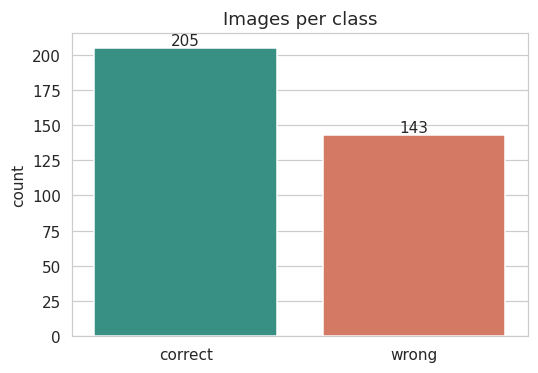

In [4]:
if DATA_SOURCE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    DATASET_ROOT = Path(DRIVE_DATASET_PATH)
elif DATA_SOURCE == "upload_zip":
    from google.colab import files
    uploaded = files.upload()                      # choose your dataset .zip
    zip_name = next(iter(uploaded))
    extract_to = Path("/content/dataset")
    shutil.rmtree(extract_to, ignore_errors=True)
    with zipfile.ZipFile(zip_name) as z:
        z.extractall(extract_to)
    DATASET_ROOT = extract_to
else:
    DATASET_ROOT = Path(DRIVE_DATASET_PATH)       # local path (when not running on Colab)


def find_class_root(root, class_names):
    # search for the folder that directly contains every class folder (case-insensitive)
    for d in [root] + sorted(p for p in root.rglob("*") if p.is_dir()):
        subs = {p.name.lower(): p for p in d.iterdir() if p.is_dir()}
        if all(c.lower() in subs for c in class_names):
            return d, {c: subs[c.lower()] for c in class_names}
    raise FileNotFoundError(f"Could not find folders {class_names} inside {root}")


DATASET_ROOT, CLASS_DIRS = find_class_root(DATASET_ROOT, CLASS_NAMES)
print("Dataset folder:", DATASET_ROOT)

records = []
for label, cname in enumerate(CLASS_NAMES):
    for p in sorted(CLASS_DIRS[cname].rglob("*")):
        if p.suffix.lower() in IMG_EXTS and not p.name.startswith("."):
            records.append({"path": str(p), "filename": p.name, "class_name": cname, "label": label})
df = pd.DataFrame(records)

# drop unreadable images
ok = [cv2.imread(p, cv2.IMREAD_REDUCED_GRAYSCALE_8) is not None for p in tqdm(df.path, desc="Checking images")]
bad = df[~np.array(ok)]
if len(bad):
    print(f" {len(bad)} unreadable files skipped:", bad.filename.tolist()[:10])
df = df[np.array(ok)].reset_index(drop=True)

print(f"\nTotal images: {len(df)}")
print(df.class_name.value_counts().to_string())

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="class_name", order=CLASS_NAMES, palette=["#2a9d8f", "#e76f51"], ax=ax)
for c in ax.containers: ax.bar_label(c)
ax.set_title("Images per class"); ax.set_xlabel(""); plt.tight_layout(); plt.show()

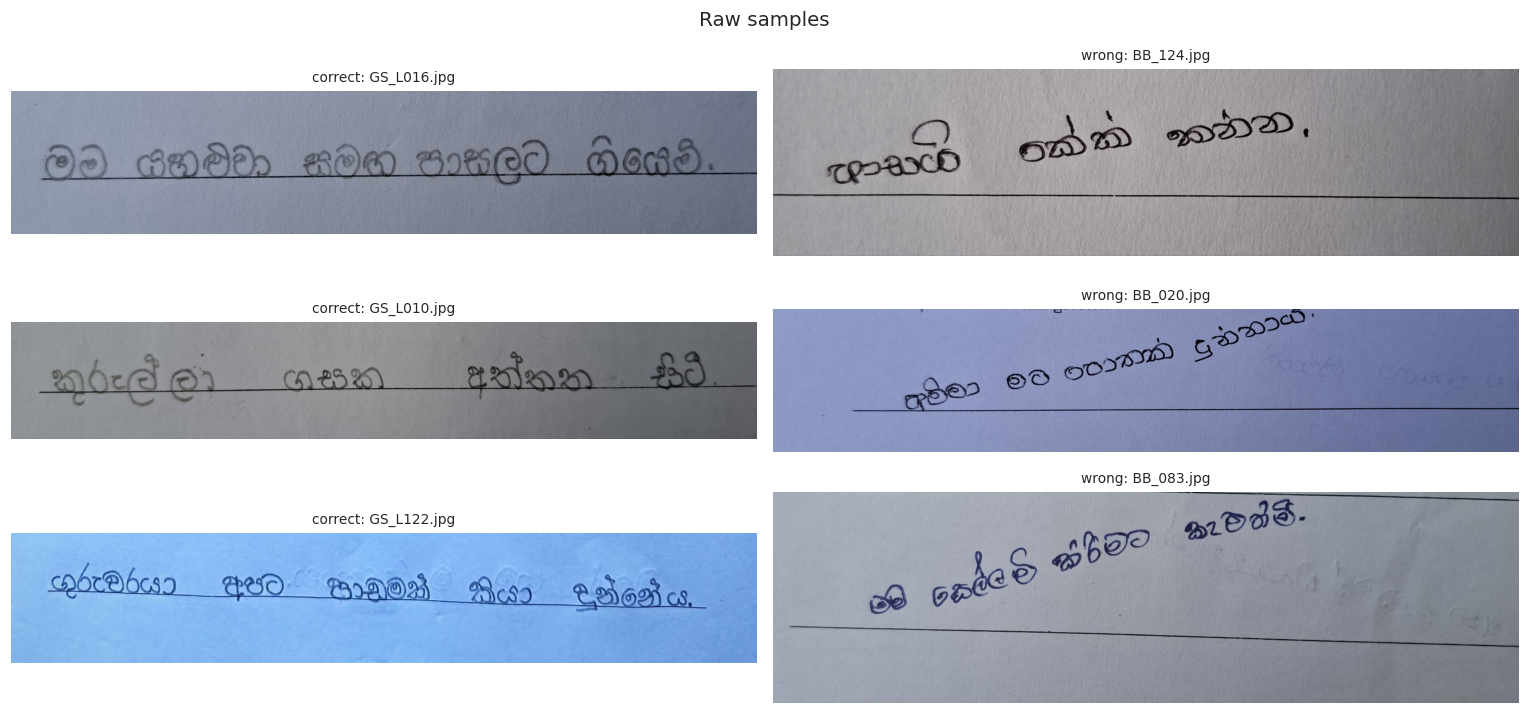

In [5]:
# a few raw samples from each class
n_show = 3
fig, axes = plt.subplots(n_show, 2, figsize=(14, 2.2 * n_show))
for col, cname in enumerate(CLASS_NAMES):
    sub = df[df.class_name == cname].sample(min(n_show, (df.class_name == cname).sum()), random_state=SEED)
    for row in range(n_show):
        ax = axes[row, col]; ax.axis("off")
        if row < len(sub):
            img = cv2.cvtColor(cv2.imread(sub.iloc[row].path), cv2.COLOR_BGR2RGB)
            ax.imshow(img); ax.set_title(f"{cname}: {sub.iloc[row].filename}", fontsize=9)
plt.suptitle("Raw samples", fontsize=13); plt.tight_layout(); plt.show()

## Step 4 — Split into train / validation / test

Stratified split (70 % / 15 % / 15 %) keeps the correct/wrong ratio the same in every split. The split is done **before** any training so the test set stays completely unseen.

In [6]:
def split_dataset(df):
    if GROUP_PATTERN:
        groups = df.filename.apply(lambda f: (re.search(GROUP_PATTERN, f) or [None, f])[1])
        print(f"Student-wise split using {groups.nunique()} groups")
        gss = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED)
        trval_idx, test_idx = next(gss.split(df, df.label, groups))
        trval = df.iloc[trval_idx]
        gss2 = GroupShuffleSplit(n_splits=1, test_size=VAL_SIZE / (TRAIN_SIZE + VAL_SIZE), random_state=SEED)
        tr_idx, val_idx = next(gss2.split(trval, trval.label, groups.iloc[trval_idx]))
        return trval.iloc[tr_idx], trval.iloc[val_idx], df.iloc[test_idx]
    trval, test = train_test_split(df, test_size=TEST_SIZE, stratify=df.label, random_state=SEED)
    train, val = train_test_split(trval, test_size=VAL_SIZE / (TRAIN_SIZE + VAL_SIZE),
                                  stratify=trval.label, random_state=SEED)
    return train, val, test


train_df, val_df, test_df = split_dataset(df)
df["split"] = ""
df.loc[train_df.index, "split"] = "train"
df.loc[val_df.index, "split"] = "val"
df.loc[test_df.index, "split"] = "test"

split_table = pd.crosstab(df.split, df.class_name).reindex(["train", "val", "test"])[CLASS_NAMES]
split_table["total"] = split_table.sum(axis=1)
split_table["% of data"] = (100 * split_table.total / len(df)).round(1)
display(split_table)
df.to_csv(WORK_DIR / "dataset_split.csv", index=False)

class_name,correct,wrong,total,% of data
split,,,,
train,143,99,242,69.5
val,31,22,53,15.2
test,31,22,53,15.2


## Step 5 — Preprocessing (grayscale, resize, lighting fix, denoise, deskew)

| Step | Why |
|---|---|
| **Grayscale** | Colour (blue paper, pen colour) is not needed to judge the baseline |
| **Resize to a fixed width** (aspect ratio kept) | Same scale for every image; *never* squash to a square — it distorts the drift |
| **CLAHE** | Fixes uneven phone-camera lighting (e.g. darker on the left) |
| **Non-local means denoise** | Removes paper texture / camera noise |
| **Adaptive threshold** | Ink = white, paper = black, robust to shadows |
| **Deskew using the printed guide line only** | Corrects a tilted camera. We *never* deskew using the handwriting, otherwise the child's real drift would be removed |

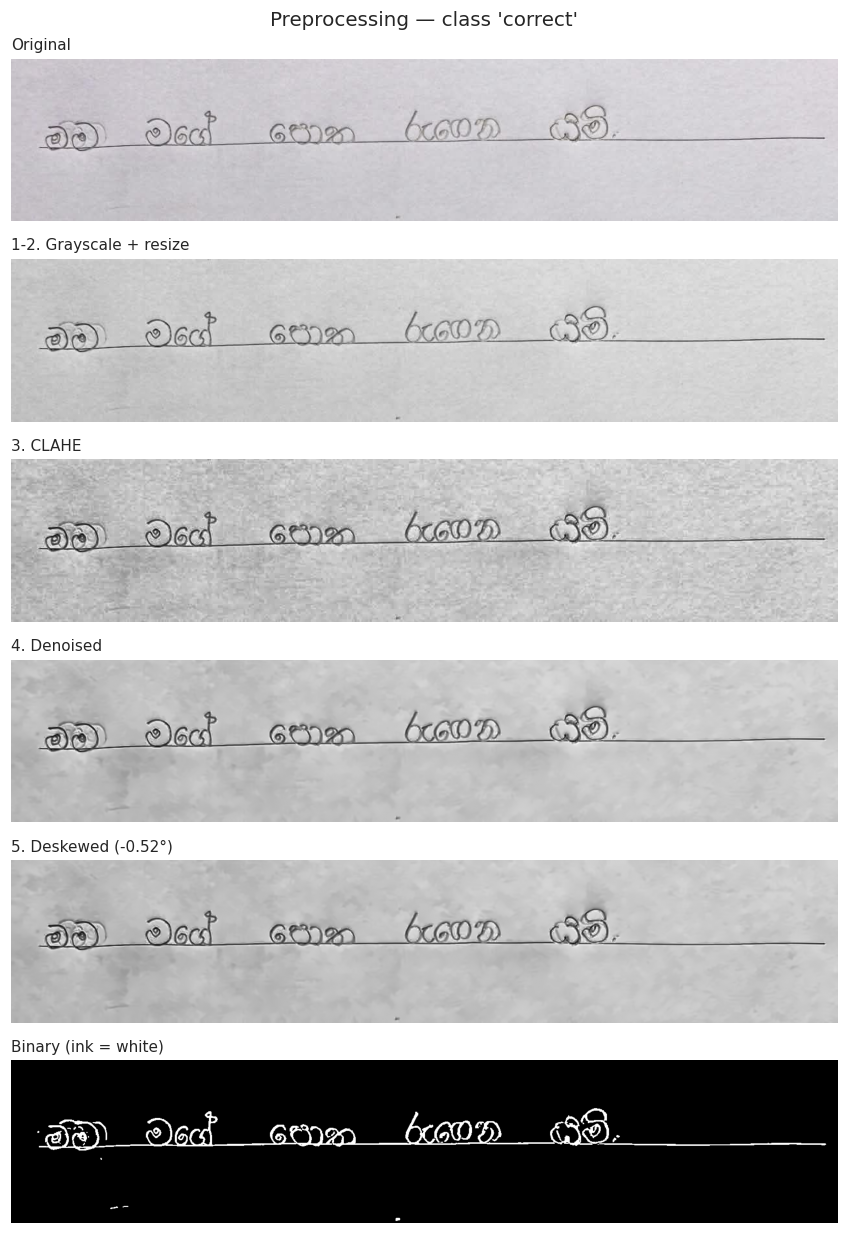

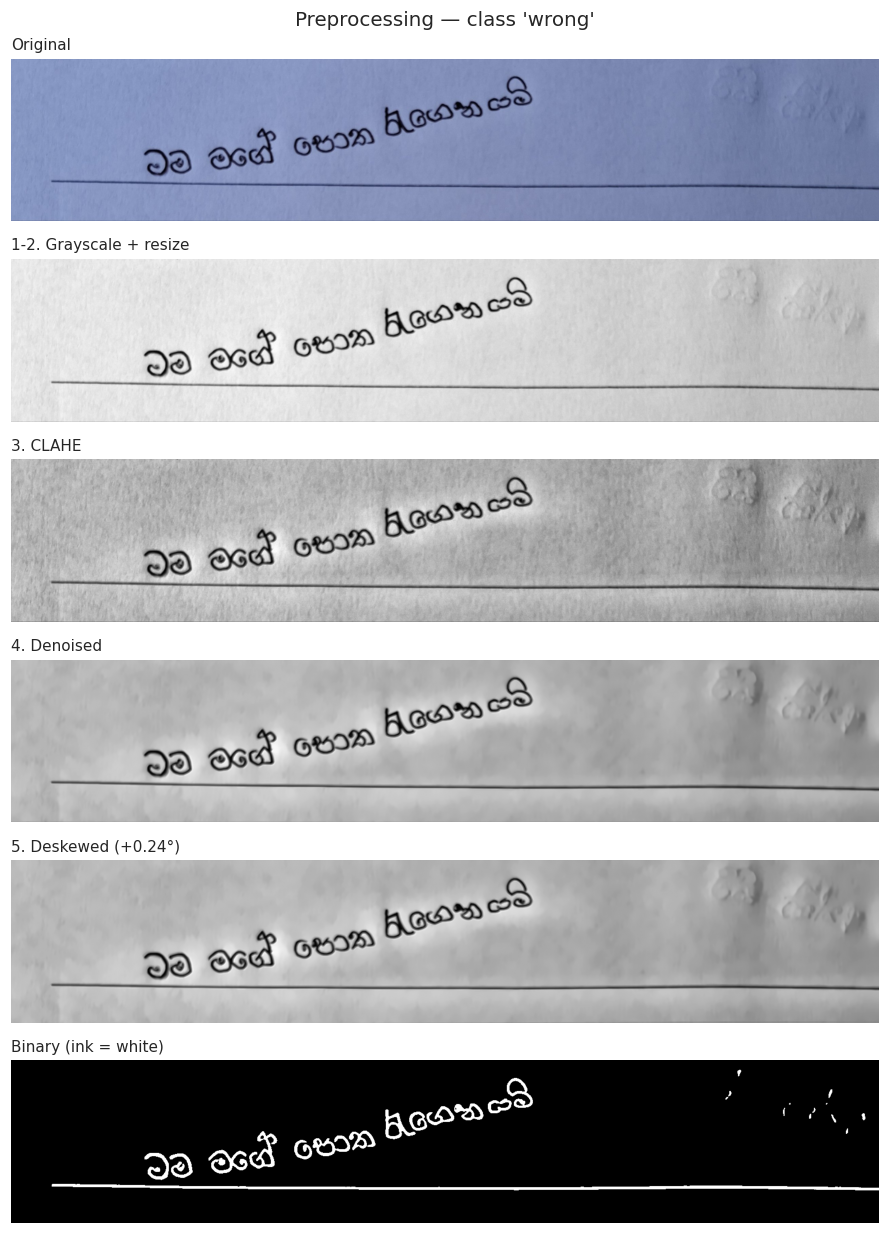

In [7]:
def binarize(img):
    binary = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY_INV, 41, 15)
    return cv2.morphologyEx(binary, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))


def guide_line_angle(binary, max_angle=20):
    # angle (degrees) of the longest near-horizontal straight line; 0 if none
    W = binary.shape[1]
    segs = cv2.HoughLinesP(binary, 1, np.pi / 720, threshold=150,
                           minLineLength=int(0.25 * W), maxLineGap=25)
    if segs is None:
        return 0.0
    angles, lengths = [], []
    for x1, y1, x2, y2 in segs.reshape(-1, 4):
        a = np.degrees(np.arctan2(y2 - y1, x2 - x1))
        if abs(a) <= max_angle:
            angles.append(a); lengths.append(np.hypot(x2 - x1, y2 - y1))
    if not angles:
        return 0.0
    order = np.argsort(angles)
    angles, lengths = np.array(angles)[order], np.array(lengths)[order]
    cum = np.cumsum(lengths)
    return float(angles[np.searchsorted(cum, cum[-1] / 2)])        # length-weighted median


def rotate(img, angle):
    h, w = img.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    return cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)


def preprocess_image(path, target_width=TARGET_WIDTH):
    # returns every intermediate stage; 'final' is the clean grayscale image used for features
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)                  # honours phone EXIF rotation
    if bgr is None:
        raise ValueError(f"Cannot read {path}")
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)                    # 1. grayscale
    h, w = gray.shape
    scale = target_width / w
    gray = cv2.resize(gray, (target_width, max(1, round(h * scale))),  # 2. resize
                      interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_CUBIC)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)   # 3. lighting
    denoised = cv2.fastNlMeansDenoising(clahe, None, h=10, templateWindowSize=7, searchWindowSize=21)  # 4.
    angle = guide_line_angle(binarize(denoised))                    # 5. deskew (guide line only)
    final = rotate(denoised, angle) if angle != 0.0 else denoised
    return {"original": cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), "gray": gray, "clahe": clahe,
            "denoised": denoised, "final": final, "binary": binarize(final), "skew_angle": angle}


# visualise the pipeline on one image from each class
for cname in CLASS_NAMES:
    p = train_df[train_df.class_name == cname].iloc[0].path
    st = preprocess_image(p)
    stages = [("Original", st["original"]), ("1-2. Grayscale + resize", st["gray"]),
              ("3. CLAHE", st["clahe"]), ("4. Denoised", st["denoised"]),
              (f"5. Deskewed ({st['skew_angle']:+.2f}°)", st["final"]), ("Binary (ink = white)", st["binary"])]
    fig, axes = plt.subplots(len(stages), 1, figsize=(12, 1.9 * len(stages)))
    for ax, (t, im) in zip(axes, stages):
        ax.imshow(im, cmap=None if im.ndim == 3 else "gray"); ax.set_title(t, fontsize=10, loc="left"); ax.axis("off")
    plt.suptitle(f"Preprocessing — class '{cname}'", fontsize=13); plt.tight_layout(); plt.show()

### Preprocess and grayscale **all** images (saved to `/content/work/preprocessed/<split>/<class>/`)

In [8]:
PRE_DIR = WORK_DIR / "preprocessed"
shutil.rmtree(PRE_DIR, ignore_errors=True)

pre_paths, skews, failed = [], [], []
for _, r in tqdm(df.iterrows(), total=len(df), desc="Preprocessing"):
    out = PRE_DIR / r.split / r.class_name / (Path(r.filename).stem + ".png")
    out.parent.mkdir(parents=True, exist_ok=True)
    try:
        st = preprocess_image(r.path)
        cv2.imwrite(str(out), st["final"])                     # clean grayscale image
        pre_paths.append(str(out)); skews.append(st["skew_angle"])
    except Exception as e:
        pre_paths.append(None); skews.append(np.nan); failed.append((r.filename, str(e)))

df["pre_path"], df["skew_angle"] = pre_paths, skews
if failed:
    print(f"⚠️ {len(failed)} images failed:", failed[:5])
df = df[df.pre_path.notna()].reset_index(drop=True)
print(f"✅ {len(df)} grayscale images saved to {PRE_DIR}")
print(f"Camera tilt corrected: mean |angle| = {df.skew_angle.abs().mean():.2f}°, max = {df.skew_angle.abs().max():.2f}°")

Preprocessing:   0%|          | 0/348 [00:00<?, ?it/s]

✅ 348 grayscale images saved to /content/work_gradient_boosting/preprocessed
Camera tilt corrected: mean |angle| = 0.56°, max = 2.24°


## Step 6 — Feature extraction with OpenCV

For each preprocessed image:
1. **Detect the printed guide line**: morphological opening with a long horizontal kernel, then a robust line fit (`cv2.fitLine`, Huber).
2. **Remove the guide line** so it does not join letters together.
3. **Group letters into words**: dilation scaled to the character height, then contours.
4. **Robust word bottom** = 85th percentile of the word's ink pixels, so Sinhala descender strokes like **ු / ූ** do not count as deviation.
5. **Gap** = distance from the word bottom to the guide line, divided by character height (positive = above the line). Dividing by character height makes big and small handwriting comparable.

If no printed line is found, a horizontal line through the first word is used as the reference (`line_found = 0`).

| Feature | Meaning |
|---|---|
| `mean_gap`, `median_gap`, `mean_abs_gap` | how far words sit from the line on average |
| `max_gap`, `min_gap`, `max_abs_gap`, `gap_range` | worst deviation above or below |
| `first_gap`, `last_gap`, `first_last_diff` | start vs end of the line |
| `drift_slope` | **rising (+) or falling (−)** trend across the line |
| `waviness`, `mean_step`, `std_gap` | up-and-down wobble between words |
| `frac_floating`, `frac_below`, `frac_on_line` | share of words above / below / on the line |
| `below_ink_ratio` | share of ink cutting below the line |
| `word_height_cv` | letter size consistency |

In [9]:
FEATURE_NAMES = ["line_found", "n_words", "mean_gap", "median_gap", "std_gap", "max_gap", "min_gap",
                 "max_abs_gap", "mean_abs_gap", "gap_range", "first_gap", "last_gap", "first_last_diff",
                 "drift_slope", "abs_drift_slope", "waviness", "mean_step", "frac_floating", "frac_below",
                 "frac_on_line", "below_ink_ratio", "word_height_cv"]


def line_candidates(binary):
    H, W = binary.shape
    k = max(40, W // 12)
    horiz = cv2.morphologyEx(binary, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (k, 1)))
    horiz = cv2.dilate(horiz, cv2.getStructuringElement(cv2.MORPH_RECT, (31, 3)))   # bridge faint gaps
    n, labels, stats, _ = cv2.connectedComponentsWithStats(horiz)
    cands = []
    for i in range(1, n):
        x, y, w, h, area = stats[i]
        if w < 0.30 * W or h > 0.15 * H:
            continue
        ys, xs = np.where(labels == i)
        vx, vy, x0, y0 = cv2.fitLine(np.column_stack([xs, ys]).astype(np.float32),
                                     cv2.DIST_HUBER, 0, 0.01, 0.01).flatten()
        slope = vy / vx if abs(vx) > 1e-6 else 0.0
        cands.append({"slope": float(slope), "intercept": float(y0 - slope * x0), "label": i})
    return cands, labels


def extract_features(gray, return_debug=False):
    binary = binarize(gray)
    H, W = binary.shape
    cands, line_labels = line_candidates(binary)

    # remove detected guide lines from the ink image
    text_bw = binary.copy()
    if cands:
        line_mask = np.isin(line_labels, [c["label"] for c in cands]).astype(np.uint8) * 255
        line_mask = cv2.dilate(cv2.bitwise_and(line_mask, binary), np.ones((3, 1), np.uint8))
        text_bw = cv2.subtract(text_bw, line_mask)
        text_bw = cv2.morphologyEx(text_bw, cv2.MORPH_CLOSE, np.ones((5, 1), np.uint8))

    # blank a thin border (paper edges / shadows) and drop noise specks
    m = max(4, int(0.01 * min(H, W)))
    text_bw[:m, :] = 0; text_bw[-m:, :] = 0; text_bw[:, :m] = 0; text_bw[:, -m:] = 0
    n, labels, stats, _ = cv2.connectedComponentsWithStats(text_bw)
    keep = np.zeros(n, bool); keep[1:] = stats[1:, cv2.CC_STAT_AREA] >= 25
    text_bw = (keep[labels] * 255).astype(np.uint8)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(text_bw)

    empty = {k: np.nan for k in FEATURE_NAMES}; empty.update(line_found=int(bool(cands)), n_words=0)
    if n <= 1:
        return (empty, None) if return_debug else empty

    # typical character height
    areas, heights = stats[1:, cv2.CC_STAT_AREA], stats[1:, cv2.CC_STAT_HEIGHT]
    big = heights[areas >= np.percentile(areas, 30)]
    char_h = max(8.0, float(np.median(big)) if len(big) else float(np.median(heights)))

    # group letters into words
    kw, kh = max(5, int(0.6 * char_h)) | 1, max(3, int(0.4 * char_h)) | 1
    merged = cv2.dilate(text_bw, cv2.getStructuringElement(cv2.MORPH_RECT, (kw, kh)))
    contours, _ = cv2.findContours(merged, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    words = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        ys, xs = np.nonzero(text_bw[y:y + h, x:x + w])
        if len(ys) < 0.15 * char_h * char_h:                   # full stops, dots, noise
            continue
        if w < 0.35 * char_h and h < 0.35 * char_h:
            continue
        if x <= m + 2 or x + w >= W - m - 2:                   # touches the page edge
            continue
        if h > 2.5 * char_h and w < 0.25 * h:                  # margin line / paper fold
            continue
        ys = ys + y
        words.append({"x": x, "y": y, "w": w, "h": h, "cx": x + w / 2.0,
                      "bottom": float(np.percentile(ys, 85)), "ys": ys})
    if not words:
        return (empty, None) if return_debug else empty
    words.sort(key=lambda d: d["cx"])
    bottoms = np.array([wd["bottom"] for wd in words])
    cxs = np.array([wd["cx"] for wd in words])

    # pick the guide line that the text is written on
    line = None
    if cands:
        def score(c):
            d = (c["slope"] * cxs + c["intercept"]) - bottoms
            return np.sum((d > -2 * char_h) & (d < 5 * char_h)) * 1000 - np.mean(np.abs(d))
        line = max(cands, key=score)
    line_y = line["slope"] * cxs + line["intercept"] if line else np.full_like(bottoms, bottoms[0])

    gaps = (line_y - bottoms) / char_h                         # + above line, − below line
    xn = (cxs - cxs.min()) / max(1.0, cxs.max() - cxs.min())   # 0 … 1 along the line
    if len(words) >= 2:
        drift, icpt = np.polyfit(xn, gaps, 1); resid = gaps - (drift * xn + icpt)
    else:
        drift, resid = 0.0, np.zeros(1)
    total_ink = sum(len(wd["ys"]) for wd in words)
    below_ink = sum(int(np.sum(wd["ys"] > ly + 0.25 * char_h)) for wd, ly in zip(words, line_y))
    hs = np.array([wd["h"] for wd in words], float)
    tol = 0.35

    f = {"line_found": int(line is not None), "n_words": len(words),
         "mean_gap": gaps.mean(), "median_gap": np.median(gaps), "std_gap": gaps.std(),
         "max_gap": gaps.max(), "min_gap": gaps.min(), "max_abs_gap": np.abs(gaps).max(),
         "mean_abs_gap": np.abs(gaps).mean(), "gap_range": gaps.max() - gaps.min(),
         "first_gap": gaps[0], "last_gap": gaps[-1], "first_last_diff": gaps[-1] - gaps[0],
         "drift_slope": drift, "abs_drift_slope": abs(drift), "waviness": resid.std(),
         "mean_step": np.abs(np.diff(gaps)).mean() if len(gaps) > 1 else 0.0,
         "frac_floating": np.mean(gaps > tol), "frac_below": np.mean(gaps < -tol),
         "frac_on_line": np.mean(np.abs(gaps) <= tol), "below_ink_ratio": below_ink / max(1, total_ink),
         "word_height_cv": hs.std() / max(1e-6, hs.mean())}
    f = {k: float(v) for k, v in f.items()}
    if not return_debug:
        return f
    return f, {"gray": gray, "words": words, "line": line, "line_y": line_y, "gaps": gaps, "char_h": char_h}


def draw_measurements(dbg):
    vis = cv2.cvtColor(dbg["gray"], cv2.COLOR_GRAY2RGB)
    W = vis.shape[1]
    if dbg["line"] is not None:
        L = dbg["line"]
        cv2.line(vis, (0, int(L["intercept"])), (W, int(L["slope"] * W + L["intercept"])), (0, 190, 0), 3)
    for wd, ly, g in zip(dbg["words"], dbg["line_y"], dbg["gaps"]):
        cv2.rectangle(vis, (wd["x"], wd["y"]), (wd["x"] + wd["w"], wd["y"] + wd["h"]), (30, 90, 255), 2)
        cx, b = int(wd["cx"]), int(wd["bottom"])
        cv2.line(vis, (cx, b), (cx, int(ly)), (230, 0, 0), 3); cv2.circle(vis, (cx, b), 6, (230, 0, 0), -1)
        cv2.putText(vis, f"{g:+.2f}", (wd["x"], max(22, wd["y"] - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.85, (230, 0, 0), 2)
    return vis

### Check what OpenCV measures (green = guide line, blue = words, red = gap in character heights)

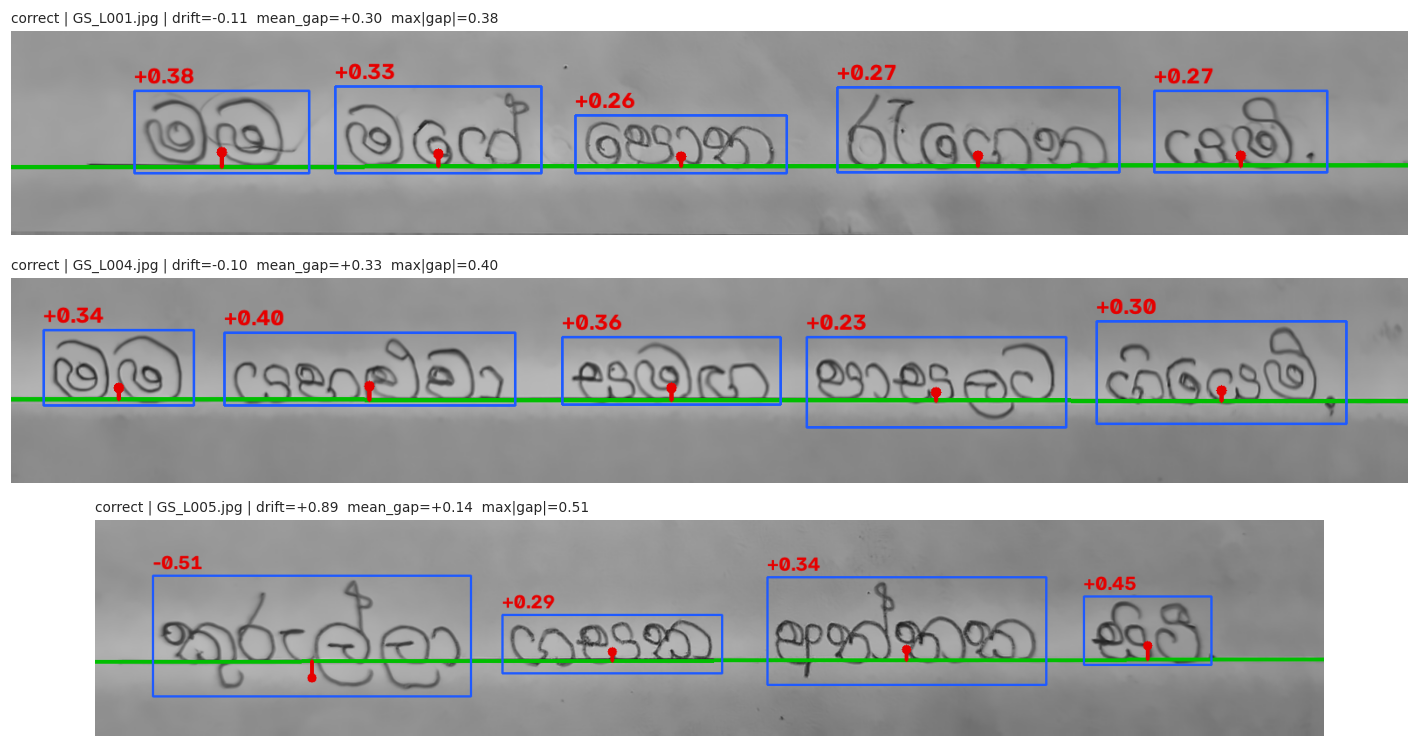

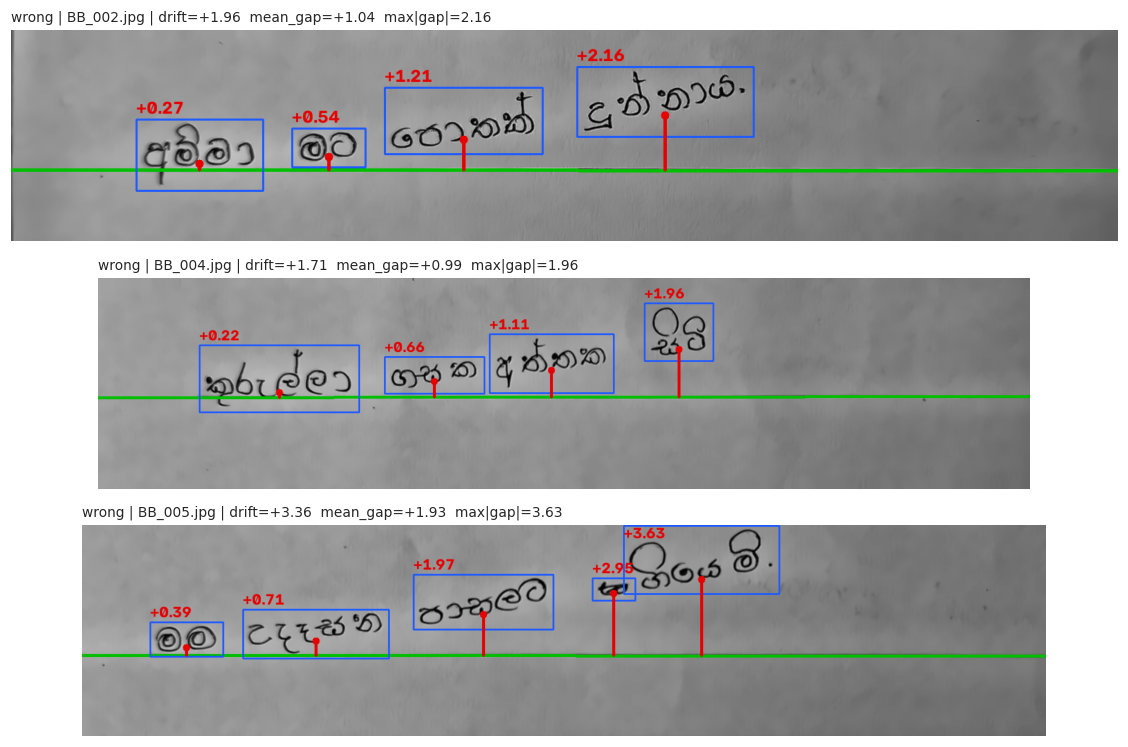

In [10]:
n_show = 3
for cname in CLASS_NAMES:
    sub = df[(df.split == "train") & (df.class_name == cname)].head(n_show)
    fig, axes = plt.subplots(len(sub), 1, figsize=(13, 2.3 * len(sub)), squeeze=False)
    for ax, (_, r) in zip(axes[:, 0], sub.iterrows()):
        f, dbg = extract_features(cv2.imread(r.pre_path, cv2.IMREAD_GRAYSCALE), return_debug=True)
        ax.imshow(draw_measurements(dbg) if dbg else cv2.imread(r.pre_path), cmap="gray"); ax.axis("off")
        ax.set_title(f"{cname} | {r.filename} | drift={f['drift_slope']:+.2f}  mean_gap={f['mean_gap']:+.2f}  "
                     f"max|gap|={f['max_abs_gap']:.2f}", fontsize=9, loc="left")
    plt.tight_layout(); plt.show()

### Extract features for all images

In [11]:
rows = []
for _, r in tqdm(df.iterrows(), total=len(df), desc="Extracting features"):
    f = extract_features(cv2.imread(r.pre_path, cv2.IMREAD_GRAYSCALE))
    rows.append({**f, "filename": r.filename, "path": r.path, "pre_path": r.pre_path,
                 "label": r.label, "class_name": r.class_name, "split": r.split})
feat_df = pd.DataFrame(rows)
feat_df.to_csv(WORK_DIR / "features.csv", index=False)

print("Guide line found in", f"{100 * feat_df.line_found.mean():.1f}% of images")
print("Images where no words were found:", int((feat_df.n_words == 0).sum()))
display(feat_df[FEATURE_NAMES + ["class_name", "split"]].head())

X_train = feat_df.loc[feat_df.split == "train", FEATURE_NAMES].values
y_train = feat_df.loc[feat_df.split == "train", "label"].values
X_val   = feat_df.loc[feat_df.split == "val",   FEATURE_NAMES].values
y_val   = feat_df.loc[feat_df.split == "val",   "label"].values
X_test  = feat_df.loc[feat_df.split == "test",  FEATURE_NAMES].values
y_test  = feat_df.loc[feat_df.split == "test",  "label"].values
print(f"\nX_train {X_train.shape} | X_val {X_val.shape} | X_test {X_test.shape}")

Extracting features:   0%|          | 0/348 [00:00<?, ?it/s]

Guide line found in 100.0% of images
Images where no words were found: 0


,line_found,n_words,mean_gap,median_gap,std_gap,max_gap,min_gap,max_abs_gap,mean_abs_gap,gap_range,...,abs_drift_slope,waviness,mean_step,frac_floating,frac_below,frac_on_line,below_ink_ratio,word_height_cv,class_name,split
0,1.0,5.0,0.302497,0.274090,0.046515,0.380549,0.258772,0.380549,0.302497,0.121777,...,0.107812,0.025902,0.035797,0.20,0.00,0.8,0.000000,0.134629,correct,train
1,1.0,5.0,0.246372,0.318444,0.103182,0.342500,0.118045,0.342500,0.246372,0.224454,...,0.257210,0.041235,0.057269,0.00,0.00,1.0,0.027161,0.215771,correct,test
2,1.0,5.0,0.231844,0.253387,0.075020,0.336016,0.126078,0.336016,0.231844,0.209937,...,0.085819,0.068768,0.115544,0.00,0.00,1.0,0.059330,0.269189,correct,val
3,1.0,5.0,0.326399,0.340964,0.056622,0.397867,0.230838,0.397867,0.326399,0.167029,...,0.096860,0.044939,0.074143,0.40,0.00,0.6,0.014855,0.157751,correct,train
4,1.0,4.0,0.144176,0.316068,0.380720,0.451857,-0.507287,0.507287,0.397820,0.959144,...,0.890798,0.182160,0.319715,0.25,0.25,0.5,0.073347,0.293128,correct,train



X_train (242, 22) | X_val (53, 22) | X_test (53, 22)


### Feature exploration (training data only)

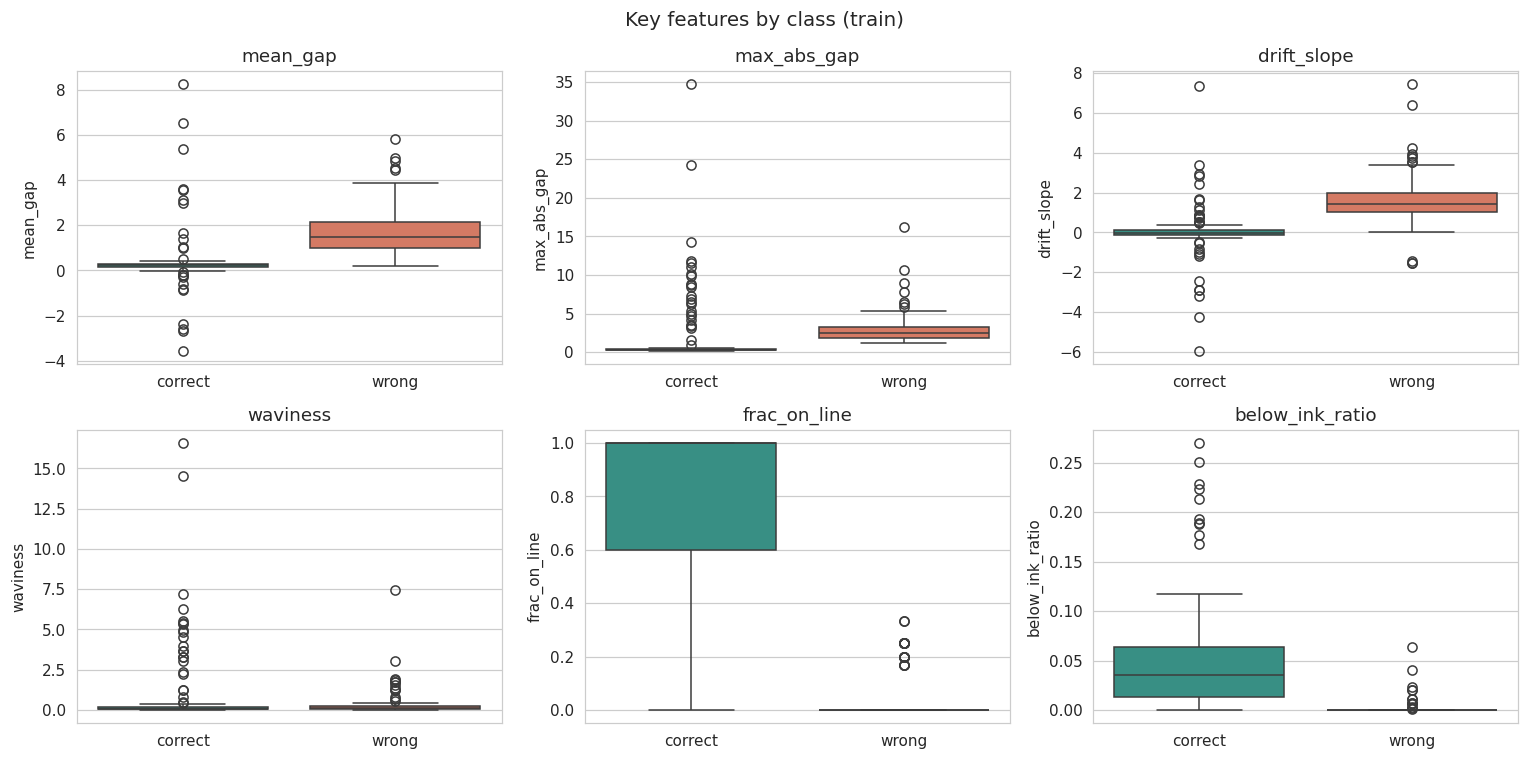

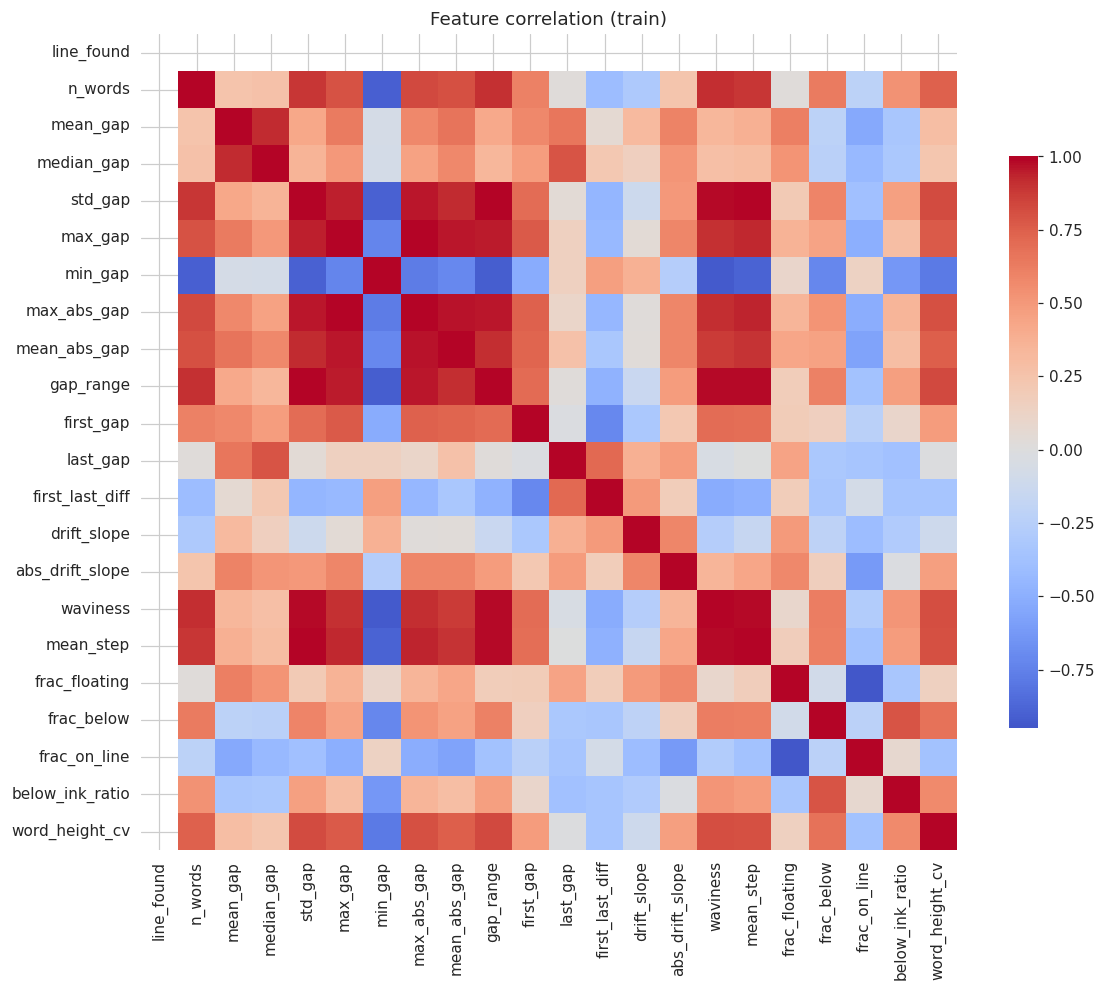

In [12]:
tr = feat_df[feat_df.split == "train"]
key = ["mean_gap", "max_abs_gap", "drift_slope", "waviness", "frac_on_line", "below_ink_ratio"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, k in zip(axes.ravel(), key):
    sns.boxplot(data=tr, x="class_name", y=k, order=CLASS_NAMES, palette=["#2a9d8f", "#e76f51"], ax=ax)
    ax.set_title(k); ax.set_xlabel("")
plt.suptitle("Key features by class (train)", fontsize=13); plt.tight_layout(); plt.show()

plt.figure(figsize=(11, 9))
sns.heatmap(tr[FEATURE_NAMES].corr(), cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Feature correlation (train)"); plt.tight_layout(); plt.show()

## Step 7 — Training & evaluation functions

The procedure:
1. **Hyperparameter tuning** with stratified k-fold cross-validation on the **training set only** (scoring = F1 for the *wrong* class)
2. Evaluation on **train / validation / test**
3. Classification report, confusion matrix, ROC and Precision–Recall curves
4. Cross-validation stability and learning curve
5. The trained model is **saved as its own file**

Gradient Boosting has no `class_weight` option, so tuning maximises the **F1-score of the "wrong" class** (which punishes minority-class mistakes) and Step 8 includes a **decision-threshold analysis** for the imbalance.

In [13]:
n_pos, n_neg = int((y_train == 1).sum()), int((y_train == 0).sum())
cv_folds = max(2, min(5, n_pos, n_neg))
CV = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=SEED)
X_trval, y_trval = np.vstack([X_train, X_val]), np.concatenate([y_train, y_val])
MODELS_DIR = WORK_DIR / "models"; MODELS_DIR.mkdir(parents=True, exist_ok=True)
print(f"Train: {n_neg} correct / {n_pos} wrong  →  {cv_folds}-fold cross-validation")


def make_pipe(clf, scale=True):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    return Pipeline(steps + [("clf", clf)])


def compute_metrics(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    both = len(np.unique(y_true)) == 2
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall / Sensitivity": recall_score(y_true, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "NPV": tn / (tn + fn) if (tn + fn) else np.nan,
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "F1 (macro)": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 (weighted)": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob) if both else np.nan,
        "PR-AUC (Avg Precision)": average_precision_score(y_true, y_prob) if both else np.nan,
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
        "Log Loss": log_loss(y_true, np.clip(y_prob, 1e-7, 1 - 1e-7), labels=[0, 1]),
        "Brier Score": brier_score_loss(y_true, y_prob),
        "False Positive Rate": fp / (fp + tn) if (fp + tn) else np.nan,
        "False Negative Rate": fn / (fn + tp) if (fn + tp) else np.nan,
        "TP": int(tp), "TN": int(tn), "FP": int(fp), "FN": int(fn),
    }


def evaluate(model, X, y):
    prob = model.predict_proba(X)[:, 1]
    pred = (prob >= 0.5).astype(int)
    return compute_metrics(y, pred, prob), pred, prob


RESULTS = {}     # filled by each experiment, used in the comparison step


def run_experiment(exp_name, clf, grid, scale=True, color="#457b9d"):
    print("=" * 78); print(f"  EXPERIMENT: {exp_name}"); print("=" * 78)

    # 1. tune + train on the training set
    t0 = time.time()
    gs = GridSearchCV(make_pipe(clf, scale), grid, scoring="f1", cv=CV, n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    model, train_time = gs.best_estimator_, time.time() - t0
    best_params = {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
    print(f"Best hyperparameters : {best_params}")
    print(f"CV F1 (training set) : {gs.best_score_:.4f} ± {gs.cv_results_['std_test_score'][gs.best_index_]:.4f}")
    print(f"Training time        : {train_time:.1f} s")

    # 2. evaluate on every split
    split_metrics, outputs = {}, {}
    for s, X, y in [("Train", X_train, y_train), ("Validation", X_val, y_val), ("Test", X_test, y_test)]:
        split_metrics[s], pred, prob = evaluate(model, X, y)
        outputs[s] = (pred, prob)
    tm = split_metrics["Test"]; test_pred, test_prob = outputs["Test"]
    print(f"\n   ✅ TEST ACCURACY : {tm['Accuracy'] * 100:.2f}%")
    print(f"   ✅ TEST F1-SCORE : {tm['F1-score']:.4f}")
    print(f"   ✅ TEST RECALL   : {tm['Recall / Sensitivity']:.4f}")
    print(f"   ✅ TEST MCC      : {tm['MCC']:.4f}\n")
    metrics_table = pd.DataFrame(split_metrics)
    display(metrics_table.style.format(lambda v: f"{v:.4f}" if isinstance(v, float) else v)
            .set_caption(f"{exp_name} — all evaluation metrics"))

    # 3. classification report
    print(f"Classification report — {exp_name} (test set)\n")
    print(classification_report(y_test, test_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))

    # 4. confusion matrix, ROC, PR
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
    pct = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    annot = np.array([[f"{cm[i, j]}\n({pct[i, j]:.1%})" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, xticklabels=CLASS_NAMES,
                yticklabels=CLASS_NAMES, ax=axes[0], annot_kws={"size": 13})
    axes[0].set(xlabel="Predicted", ylabel="Actual", title="Confusion matrix (test)")
    if len(np.unique(y_test)) == 2:
        fpr, tpr, _ = roc_curve(y_test, test_prob)
        axes[1].plot(fpr, tpr, lw=2.5, color=color, label=f"AUC = {tm['ROC-AUC']:.4f}")
        prec, rec, _ = precision_recall_curve(y_test, test_prob)
        axes[2].plot(rec, prec, lw=2.5, color=color, label=f"AP = {tm['PR-AUC (Avg Precision)']:.4f}")
        axes[2].axhline(y_test.mean(), ls="--", color="gray", label=f"Baseline = {y_test.mean():.2f}")
    axes[1].plot([0, 1], [0, 1], "k--", lw=1)
    axes[1].set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="ROC curve (test)")
    axes[2].set(xlabel="Recall", ylabel="Precision", title="Precision–Recall curve (test)")
    axes[1].legend(); axes[2].legend()
    plt.suptitle(exp_name, fontsize=14); plt.tight_layout(); plt.show()

    # 5. cross-validation stability (train + validation) and learning curve
    k = max(2, min(10, int((y_trval == 1).sum()), int((y_trval == 0).sum())))
    cvr = cross_validate(model, X_trval, y_trval, cv=StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED),
                         scoring=["accuracy", "balanced_accuracy", "precision", "recall", "f1", "roc_auc"])
    cv_summary = pd.DataFrame({m.replace("test_", ""): [cvr[m].mean(), cvr[m].std()]
                               for m in cvr if m.startswith("test_")}, index=["mean", "std"]).T
    sizes, tr_sc, va_sc = learning_curve(model, X_trval, y_trval, scoring="f1", n_jobs=-1,
                                         cv=StratifiedKFold(n_splits=min(5, k), shuffle=True, random_state=SEED),
                                         train_sizes=np.linspace(0.2, 1.0, 6), random_state=SEED, shuffle=True)
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    cv_summary["mean"].plot.bar(yerr=cv_summary["std"], capsize=4, rot=30, color=color, ax=axes[0])
    axes[0].set_ylim(0, 1.05); axes[0].set_title(f"{k}-fold cross-validation (mean ± std)")
    for sc, lbl, c in [(tr_sc, "Training", "#e76f51"), (va_sc, "Cross-validation", "#2a9d8f")]:
        axes[1].plot(sizes, sc.mean(1), "o-", color=c, label=lbl)
        axes[1].fill_between(sizes, sc.mean(1) - sc.std(1), sc.mean(1) + sc.std(1), alpha=.15, color=c)
    axes[1].set(xlabel="Training samples", ylabel="F1-score", ylim=(0, 1.05), title="Learning curve")
    axes[1].legend(); plt.suptitle(exp_name, fontsize=14); plt.tight_layout(); plt.show()
    display(cv_summary.style.format("{:.4f}").set_caption(f"{exp_name} — {k}-fold cross-validation"))

    # 6. save this experiment's model as its own file
    slug = re.sub(r"[^a-z0-9]+", "_", exp_name.lower()).strip("_")
    model_path = MODELS_DIR / f"{slug}.joblib"
    joblib.dump({"model": model, "model_name": exp_name, "feature_names": FEATURE_NAMES,
                 "class_names": CLASS_NAMES, "threshold": 0.5, "target_width": TARGET_WIDTH,
                 "best_params": best_params}, model_path)
    metrics_table.to_csv(MODELS_DIR / f"{slug}_metrics.csv")
    print(f"\n💾 Model saved: {model_path}")

    RESULTS[exp_name] = {"model": model, "metrics": split_metrics, "test_pred": test_pred, "test_prob": test_prob,
                         "best_params": best_params, "cv_f1": gs.best_score_, "train_time": train_time,
                         "cv_summary": cv_summary, "color": color, "path": model_path}
    return model

Train: 143 correct / 99 wrong  →  5-fold cross-validation


## Step 8 — Train & evaluate: OpenCV + Gradient Boosting 🚀

Tuned with stratified cross-validation on the **training set only** (scoring = F1 of the *wrong* class).

| Hyperparameter | Options | Meaning |
|---|---|---|
| `n_estimators` | 100, 200, 300 | number of boosting rounds (trees added one after another) |
| `learning_rate` | 0.03, 0.1, 0.2 | how much each tree contributes — small values need more trees but overfit less |
| `max_depth` | 1, 2, 3 | depth of each tree (boosting works best with *shallow* trees) |
| `subsample` | 0.7, 1.0 | fraction of images used per tree (< 1 adds randomness and reduces overfitting) |

> ⏱️ 54 settings × 5 folds — about a minute or two on Colab.

  EXPERIMENT: OpenCV + Gradient Boosting
Best hyperparameters : {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.7}
CV F1 (training set) : 0.9610 ± 0.0249
Training time        : 82.8 s

   ✅ TEST ACCURACY : 98.11%
   ✅ TEST F1-SCORE : 0.9767
   ✅ TEST RECALL   : 0.9545
   ✅ TEST MCC      : 0.9616



,Train,Validation,Test
Accuracy,0.9959,1.0000,0.9811
Balanced Accuracy,0.9965,1.0000,0.9773
Precision,0.9900,1.0000,1.0000
Recall / Sensitivity,1.0000,1.0000,0.9545
Specificity,0.9930,1.0000,1.0000
NPV,1.0000,1.0000,0.9688
F1-score,0.9950,1.0000,0.9767
F1 (macro),0.9957,1.0000,0.9804
F1 (weighted),0.9959,1.0000,0.9811
ROC-AUC,1.0000,1.0000,0.9956


Classification report — OpenCV + Gradient Boosting (test set)

              precision    recall  f1-score   support

     correct     0.9688    1.0000    0.9841        31
       wrong     1.0000    0.9545    0.9767        22

    accuracy                         0.9811        53
   macro avg     0.9844    0.9773    0.9804        53
weighted avg     0.9817    0.9811    0.9811        53



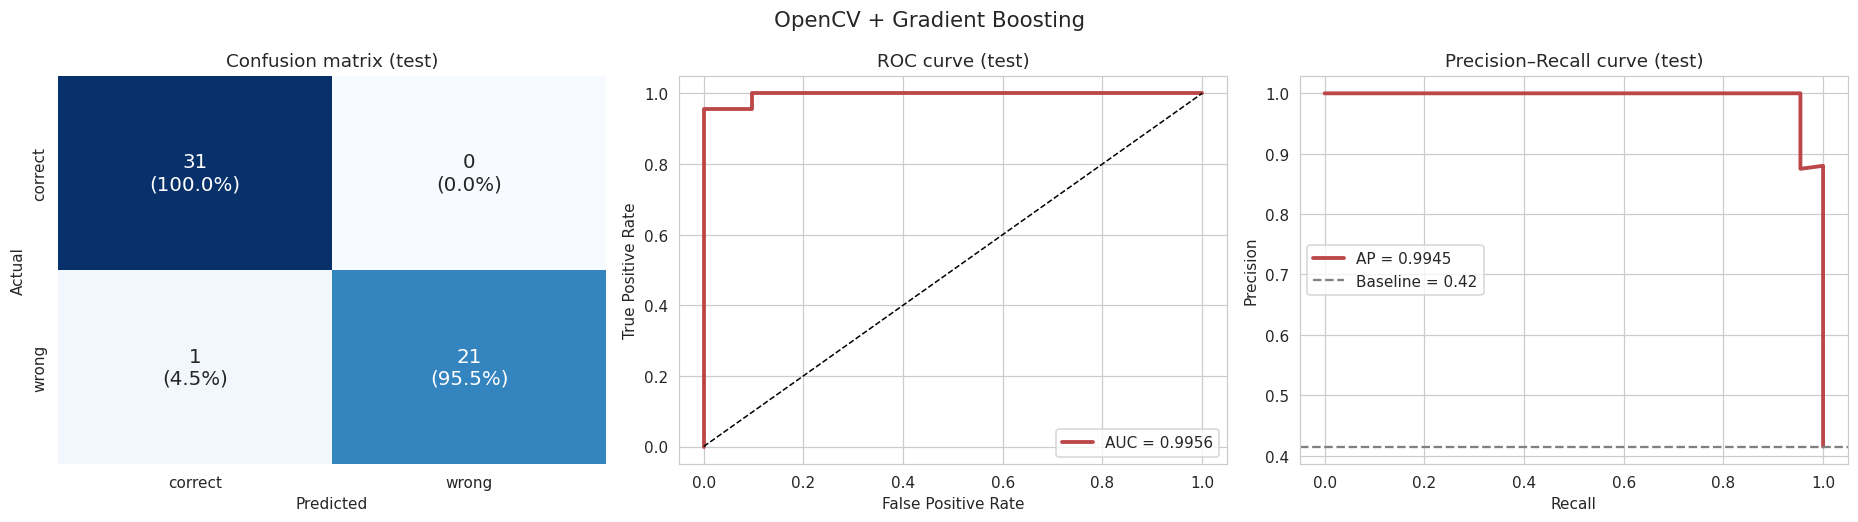

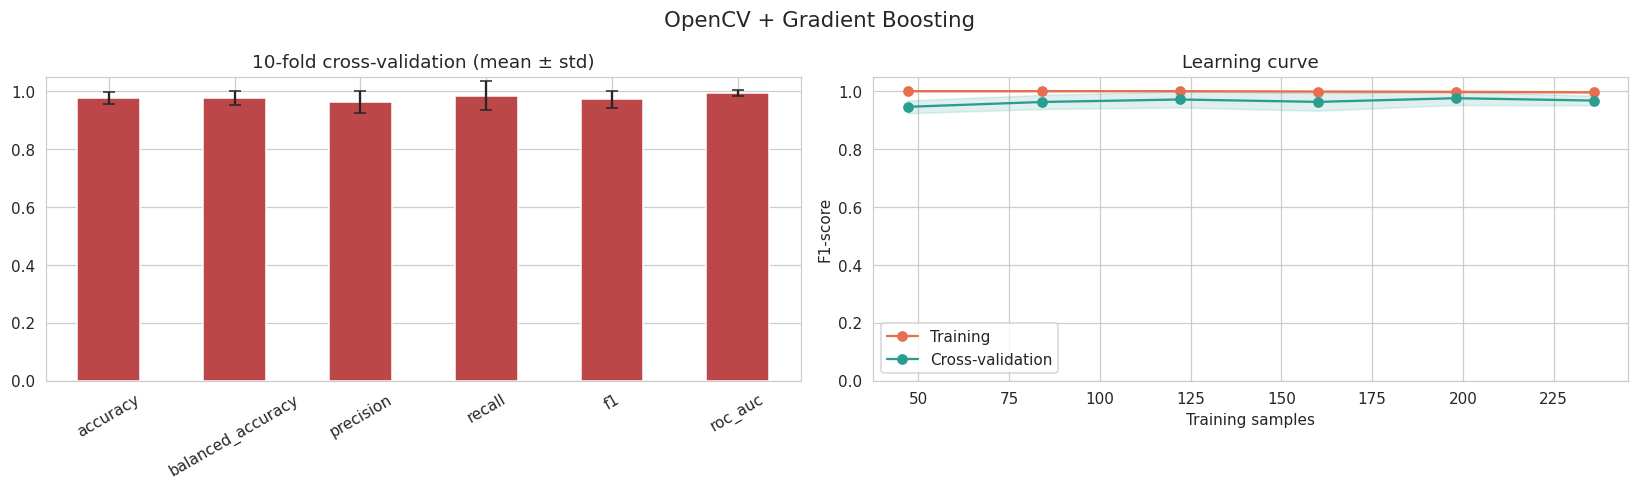

,mean,std
accuracy,0.9762,0.0219
balanced_accuracy,0.9773,0.0243
precision,0.9621,0.0379
recall,0.9833,0.0500
f1,0.9712,0.0278
roc_auc,0.9944,0.0109



💾 Model saved: /content/work_gradient_boosting/models/opencv_gradient_boosting.joblib
Boosting: 100 rounds | learning_rate = 0.03 | max_depth = 2 | subsample = 0.7


In [14]:
GB_NAME = "OpenCV + Gradient Boosting"

gb_model = run_experiment(
    GB_NAME,
    GradientBoostingClassifier(random_state=SEED),
    {"clf__n_estimators": [100, 200, 300],
     "clf__learning_rate": [0.03, 0.1, 0.2],
     "clf__max_depth": [1, 2, 3],
     "clf__subsample": [0.7, 1.0]},
    scale=False, color="#bc4749")

gb_clf = gb_model.named_steps["clf"]
pre = gb_model[:-1]                                            # imputer
print(f"Boosting: {gb_clf.n_estimators} rounds | learning_rate = {gb_clf.learning_rate} | "
      f"max_depth = {gb_clf.max_depth} | subsample = {gb_clf.subsample}")

### Training / validation / testing curves per boosting iteration

This is the boosting version of a CNN's "epoch" curves: how the score changes as trees are added **one by one**.
* **Loss (log loss):** training loss keeps falling; if *validation* loss starts rising, extra trees are only memorising the training images (the ★ marks the iteration with the lowest validation loss).
* **Accuracy / F1:** how many correct predictions at each iteration.

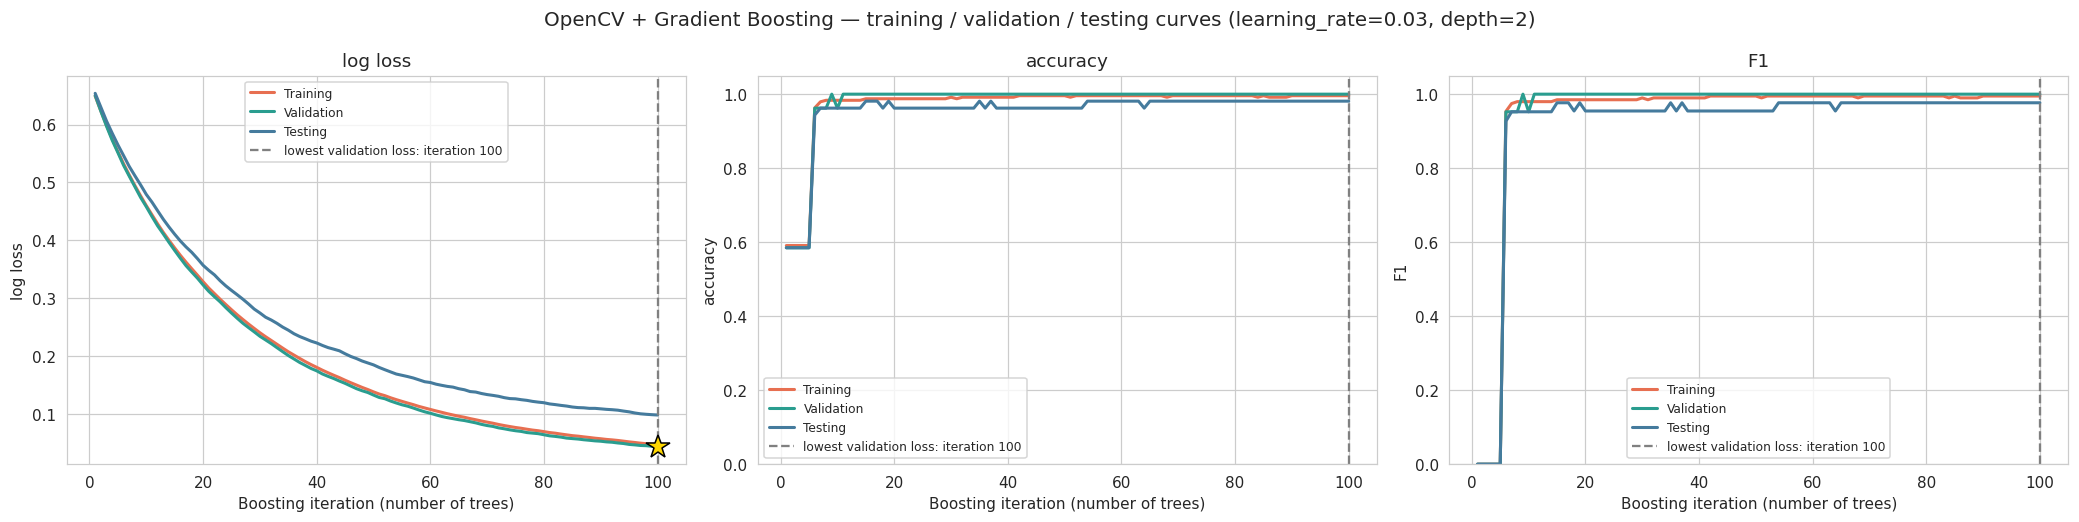

The model uses all 100 trees chosen by cross-validation; validation loss is lowest at iteration 100.


In [15]:
splits = [("Training", X_train, y_train), ("Validation", X_val, y_val), ("Testing", X_test, y_test)]
stage = {}
for s, X, y in splits:
    probs_by_stage = np.array([p[:, 1] for p in gb_clf.staged_predict_proba(pre.transform(X))])   # (iterations, images)
    stage[s] = {"accuracy": [accuracy_score(y, (p >= 0.5).astype(int)) for p in probs_by_stage],
                "F1": [f1_score(y, (p >= 0.5).astype(int), zero_division=0) for p in probs_by_stage],
                "log loss": [log_loss(y, np.clip(p, 1e-7, 1 - 1e-7), labels=[0, 1]) for p in probs_by_stage]}
n_iter = len(stage["Training"]["accuracy"])
iters = np.arange(1, n_iter + 1)
gb_curves = pd.DataFrame({f"{s} {m}": stage[s][m] for s in stage for m in stage[s]}, index=iters)
gb_curves.index.name = "iteration"
best_iter = int(np.argmin(stage["Validation"]["log loss"])) + 1

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for ax, metric in zip(axes, ["log loss", "accuracy", "F1"]):
    for s, c in [("Training", "#e76f51"), ("Validation", "#2a9d8f"), ("Testing", "#457b9d")]:
        ax.plot(iters, stage[s][metric], color=c, lw=2, label=s)
    ax.axvline(best_iter, ls="--", color="gray", label=f"lowest validation loss: iteration {best_iter}")
    ax.set(xlabel="Boosting iteration (number of trees)", ylabel=metric, title=metric)
    if metric != "log loss":
        ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8)
axes[0].plot(best_iter, stage["Validation"]["log loss"][best_iter - 1], "*", color="gold", ms=16, mec="k")
plt.suptitle(f"{GB_NAME} — training / validation / testing curves "
             f"(learning_rate={gb_clf.learning_rate}, depth={gb_clf.max_depth})", fontsize=13)
plt.tight_layout(); plt.show()
print(f"The model uses all {n_iter} trees chosen by cross-validation; validation loss is lowest at iteration {best_iter}.")

### Feature importance — which OpenCV measurements matter most?
Left: the model's own importance (how much each feature reduced the loss). Right: permutation importance on the validation set (drop in F1 when a feature is shuffled) — the more reliable of the two.

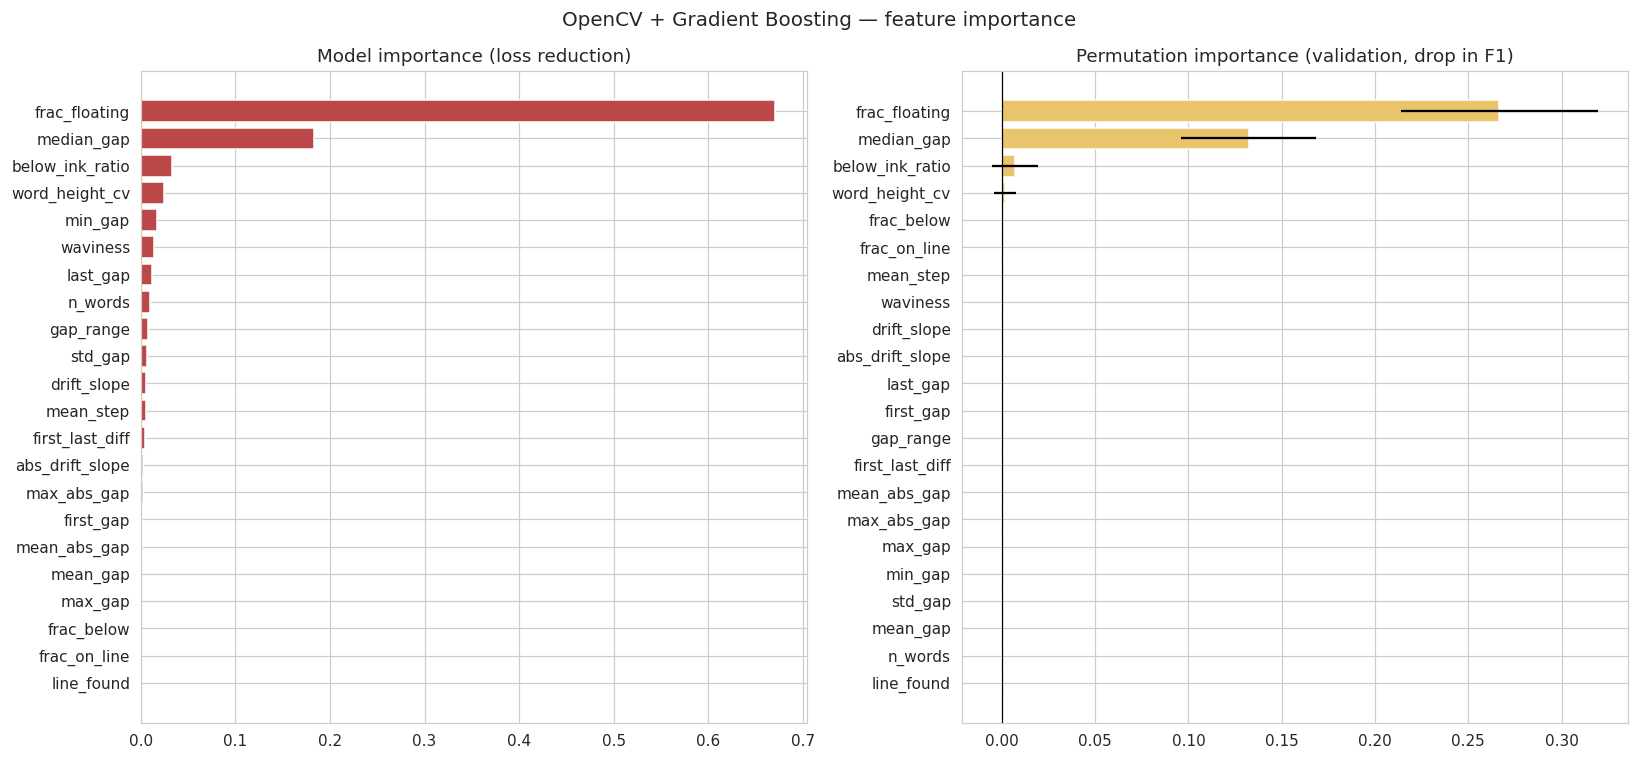

,feature,model_importance,permutation_importance,permutation_std
0,frac_floating,0.6713,0.2666,0.0528
1,median_gap,0.1830,0.1323,0.0363
2,below_ink_ratio,0.0325,0.0070,0.0124
3,word_height_cv,0.0248,0.0016,0.0058
4,min_gap,0.0165,0.0000,0.0000
5,waviness,0.0142,0.0000,0.0000
6,last_gap,0.0122,0.0000,0.0000
7,n_words,0.0098,0.0000,0.0000


In [16]:
perm = permutation_importance(gb_model, X_val, y_val, scoring="f1", n_repeats=30, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"feature": FEATURE_NAMES, "model_importance": gb_clf.feature_importances_,
                    "permutation_importance": perm.importances_mean, "permutation_std": perm.importances_std})
imp.sort_values("model_importance", ascending=False).to_csv(WORK_DIR / "feature_importance.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
a = imp.sort_values("model_importance")
axes[0].barh(a.feature, a.model_importance, color="#bc4749"); axes[0].set_title("Model importance (loss reduction)")
b = imp.sort_values("permutation_importance")
axes[1].barh(b.feature, b.permutation_importance, xerr=b.permutation_std, color="#e9c46a")
axes[1].axvline(0, color="k", lw=.8); axes[1].set_title("Permutation importance (validation, drop in F1)")
plt.suptitle(f"{GB_NAME} — feature importance", fontsize=13); plt.tight_layout(); plt.show()
display(imp.sort_values("model_importance", ascending=False).head(8).round(4).reset_index(drop=True))

### Partial dependence — how does each top feature change the prediction?
Shows the average predicted probability of **wrong** as one OpenCV measurement changes while the others stay as they are. A rising line means larger values of that measurement push the model towards "wrong".

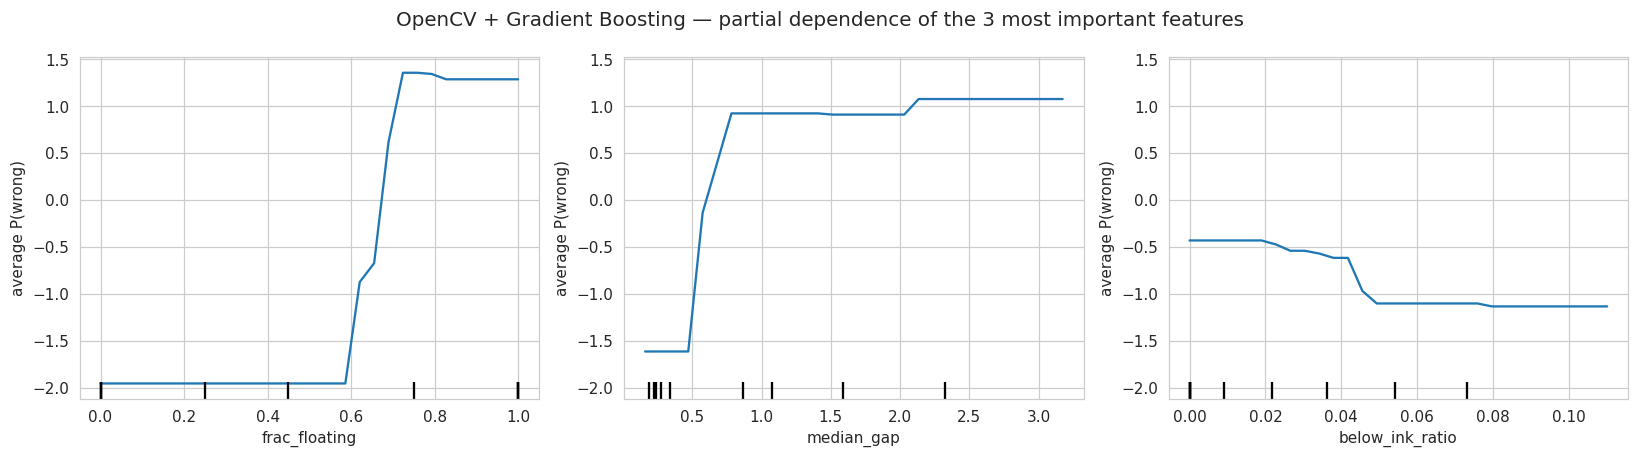

In [17]:
from sklearn.inspection import PartialDependenceDisplay
top_features = list(imp.sort_values("permutation_importance", ascending=False).feature[:3])
try:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    PartialDependenceDisplay.from_estimator(gb_clf, pre.transform(X_train), [FEATURE_NAMES.index(f) for f in top_features],
                                            feature_names=FEATURE_NAMES, ax=axes, kind="average", grid_resolution=30)
    for ax in axes: ax.set_ylabel("average P(wrong)")
    plt.suptitle(f"{GB_NAME} — partial dependence of the 3 most important features", fontsize=13)
    plt.tight_layout(); plt.show()
except Exception as e:
    plt.close("all"); print("Partial-dependence plot skipped:", e)

### Decision-threshold analysis (validation set)
The default threshold is 0.5. Because the classes are imbalanced and Gradient Boosting has no class weights, a lower threshold may catch more **wrong** samples. The threshold is chosen on the **validation** set only; the test set is just used to report.

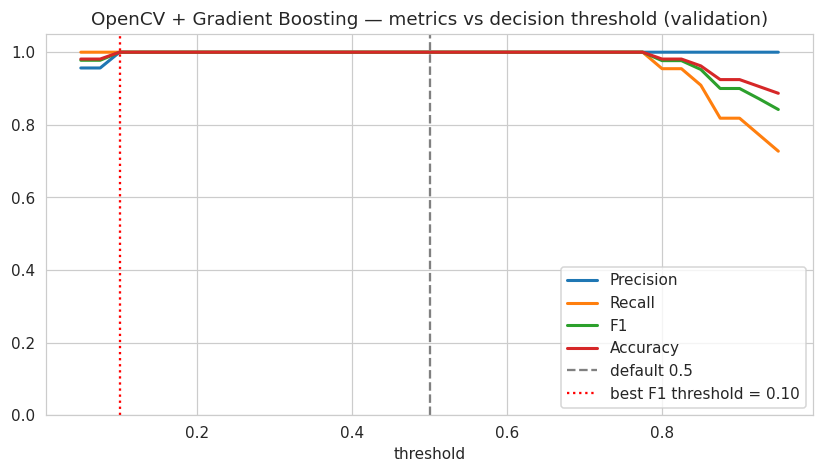

,Accuracy,Precision,Recall / Sensitivity,Specificity,F1-score,MCC
threshold = 0.50,0.9811,1.0000,0.9545,1.0000,0.9767,0.9616
threshold = 0.10,0.9245,0.8462,1.0000,0.8710,0.9167,0.8585


In [18]:
val_prob = gb_model.predict_proba(X_val)[:, 1]
ths = np.linspace(0.05, 0.95, 37)
th_df = pd.DataFrame([{"threshold": t,
                       "Precision": precision_score(y_val, (val_prob >= t).astype(int), zero_division=0),
                       "Recall": recall_score(y_val, (val_prob >= t).astype(int), zero_division=0),
                       "F1": f1_score(y_val, (val_prob >= t).astype(int), zero_division=0),
                       "Accuracy": accuracy_score(y_val, (val_prob >= t).astype(int))} for t in ths])
best_th = float(th_df.loc[th_df.F1.idxmax(), "threshold"])
th_df.plot(x="threshold", figsize=(9, 4.5), lw=2)
plt.axvline(0.5, ls="--", color="gray", label="default 0.5")
plt.axvline(best_th, ls=":", color="red", label=f"best F1 threshold = {best_th:.2f}")
plt.title(f"{GB_NAME} — metrics vs decision threshold (validation)"); plt.legend(); plt.ylim(0, 1.05); plt.show()

test_prob_gb = RESULTS[GB_NAME]["test_prob"]
tm = RESULTS[GB_NAME]["metrics"]["Test"]
tuned = compute_metrics(y_test, (test_prob_gb >= best_th).astype(int), test_prob_gb)
display(pd.DataFrame({"threshold = 0.50": tm, f"threshold = {best_th:.2f}": tuned})
        .T[["Accuracy", "Precision", "Recall / Sensitivity", "Specificity", "F1-score", "MCC"]]
        .style.format("{:.4f}").set_caption("Test set with default vs tuned threshold"))

### Misclassified test images (green line = guide line, red = measured gap in character heights)

1 of 53 test images misclassified


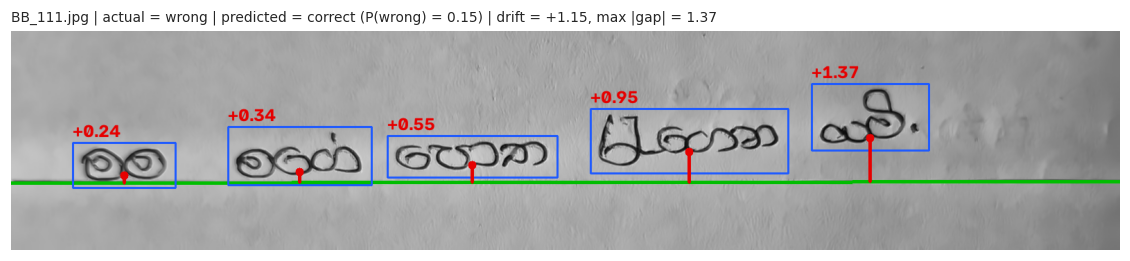

In [19]:
test_rows = feat_df[feat_df.split == "test"].reset_index(drop=True)
test_pred, test_prob = RESULTS[GB_NAME]["test_pred"], RESULTS[GB_NAME]["test_prob"]
wrong_idx = list(np.where(test_pred != y_test)[0])
print(f"{len(wrong_idx)} of {len(y_test)} test images misclassified")
for i in wrong_idx[:6]:
    r = test_rows.iloc[i]
    f, dbg = extract_features(cv2.imread(r.pre_path, cv2.IMREAD_GRAYSCALE), return_debug=True)
    plt.figure(figsize=(13, 2.6))
    plt.imshow(draw_measurements(dbg) if dbg else cv2.imread(r.pre_path, 0), cmap="gray"); plt.axis("off")
    plt.title(f"{r.filename} | actual = {CLASS_NAMES[y_test[i]]} | predicted = {CLASS_NAMES[test_pred[i]]} "
              f"(P(wrong) = {test_prob[i]:.2f}) | drift = {f['drift_slope']:+.2f}, max |gap| = {f['max_abs_gap']:.2f}",
              fontsize=9, loc="left")
    plt.show()

## Step 9 — Save and download the model and all results (separate folder)
Everything goes to **`baseline_results_gradient_boosting`** — separate from the Decision Tree, KNN, Random Forest, SVM and MobileNetV3 results.

In [20]:
SAVE_PREPROCESSED = False        # True = also zip the preprocessed grayscale images (large; same images as the other notebooks)

res = RESULTS[GB_NAME]
pd.DataFrame(res["metrics"]).to_csv(WORK_DIR / "gradient_boosting_metrics.csv")
gb_curves.to_csv(WORK_DIR / "curves_per_iteration.csv")
pd.DataFrame({"filename": test_rows.filename, "actual": [CLASS_NAMES[i] for i in y_test],
              "predicted": [CLASS_NAMES[i] for i in test_pred], "p_wrong": test_prob.round(4)}) \
  .to_csv(WORK_DIR / "test_predictions.csv", index=False)
with open(WORK_DIR / "summary.json", "w") as fh:
    json.dump({"experiment": GB_NAME,
               "test_metrics": {k: float(v) for k, v in res["metrics"]["Test"].items()},
               "best_params": {k: str(v) for k, v in res["best_params"].items()},
               "best_f1_threshold_on_validation": best_th,
               "lowest_validation_loss_iteration": best_iter,
               "cv_f1_train": float(res["cv_f1"]), "train_time_s": round(res["train_time"], 2),
               "model_file": res["path"].name,
               "n_train": len(y_train), "n_val": len(y_val), "n_test": len(y_test)}, fh, indent=2)

results_dir = Path("/content/opencv_gradient_boosting_results")
shutil.rmtree(results_dir, ignore_errors=True)
shutil.copytree(MODELS_DIR, results_dir / "models")
shutil.copytree(FIG_DIR, results_dir / "figures")
for p in WORK_DIR.glob("*.*"):
    shutil.copy(p, results_dir / p.name)
shutil.make_archive("/content/opencv_gradient_boosting_results", "zip", results_dir)
if SAVE_PREPROCESSED:
    shutil.make_archive("/content/preprocessed_dataset_gb", "zip", WORK_DIR / "preprocessed")

print("Contents of opencv_gradient_boosting_results.zip:")
for p in sorted(results_dir.rglob("*.*")): print("  ", p.relative_to(results_dir))

if DATA_SOURCE == "drive":
    dst = Path(SAVE_TO_DRIVE_DIR)
    shutil.copytree(results_dir, dst, dirs_exist_ok=True)
    shutil.copy("/content/opencv_gradient_boosting_results.zip", dst)
    if SAVE_PREPROCESSED:
        shutil.copy("/content/preprocessed_dataset_gb.zip", dst)
    print("\n📁 Results saved to Google Drive:", dst)

try:
    from google.colab import files
    files.download("/content/opencv_gradient_boosting_results.zip")
    if SAVE_PREPROCESSED:
        files.download("/content/preprocessed_dataset_gb.zip")
except ImportError:
    pass

Contents of opencv_gradient_boosting_results.zip:
   curves_per_iteration.csv
   dataset_split.csv
   feature_importance.csv
   features.csv
   figures/01_images_per_class.png
   figures/02_raw_samples.png
   figures/03_preprocessing_class_correct.png
   figures/04_preprocessing_class_wrong.png
   figures/05_figure.png
   figures/06_figure.png
   figures/07_key_features_by_class_train.png
   figures/08_feature_correlation_train.png
   figures/09_opencv_gradient_boosting.png
   figures/10_opencv_gradient_boosting.png
   figures/11_opencv_gradient_boosting_training_validation_testi.png
   figures/12_opencv_gradient_boosting_feature_importance.png
   figures/13_opencv_gradient_boosting_partial_dependence_of_the.png
   figures/14_opencv_gradient_boosting_metrics_vs_decision_thres.png
   figures/15_figure.png
   gradient_boosting_metrics.csv
   models/opencv_gradient_boosting.joblib
   models/opencv_gradient_boosting_metrics.csv
   summary.json
   test_predictions.csv

📁 Results saved to Go

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 10 — Predict a new handwriting image

Saving photo_2026-10-24_17-29-14.jpg to photo_2026-10-24_17-29-14.jpg


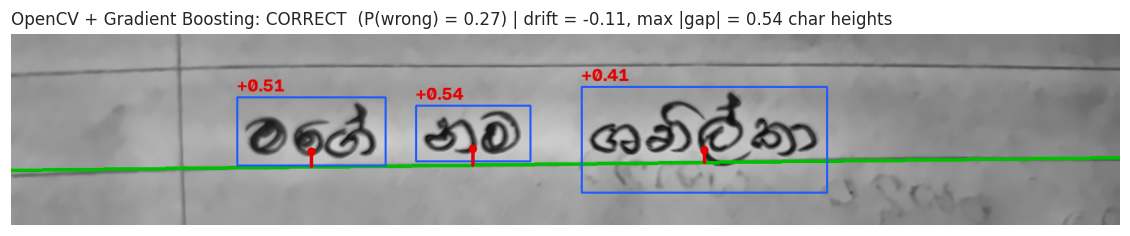

In [24]:
def predict_image(path, model=gb_model):
    st = preprocess_image(path)
    f, dbg = extract_features(st["final"], return_debug=True)
    x = np.array([[f[k] for k in FEATURE_NAMES]])
    p_wrong = float(model.predict_proba(x)[0, 1])
    label = CLASS_NAMES[int(p_wrong >= 0.5)]
    plt.figure(figsize=(13, 2.8))
    plt.imshow(draw_measurements(dbg) if dbg else st["final"], cmap="gray"); plt.axis("off")
    plt.title(f"{GB_NAME}: {label.upper()}  (P(wrong) = {p_wrong:.2f}) | drift = {f['drift_slope']:+.2f}, "
              f"max |gap| = {f['max_abs_gap']:.2f} char heights", fontsize=11, loc="left")
    plt.show()
    return label, p_wrong


try:
    from google.colab import files
    for name in files.upload():                     # choose one or more images
        predict_image(name)
except ImportError:
    predict_image(feat_df[feat_df.split == "test"].iloc[0].path)